In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def execute_and_plot(circuit, shots):
    # Import the AerSimulator from Qiskit Aer for simulating quantum circuits
    backend = AerSimulator(method="statevector")  # Use the statevector method for full quantum state simulation
    # Transpile the quantum circuit to optimize it for the chosen backend
    qc_compiled = transpile(circuit, backend)

    # Run the original (not transpiled) circuit on the simulator with 32 shots (repetitions)
    job_sim = backend.run(circuits=circuit, shots=shots)

    # Retrieve the result of the simulation job
    result = job_sim.result()

    # Extract the counts (measurement outcomes and their frequencies) from the result
    counts = result.get_counts(circuit)

    # Plot a histogram of the measurement results
    return plot_histogram(counts)


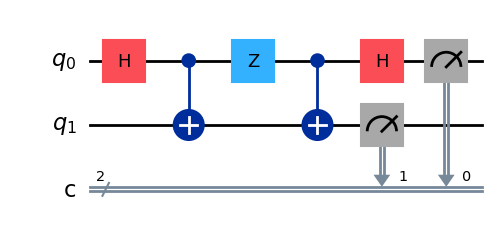

In [ ]:
# Superdense Coding Quantum Circuit Example
# a quantum communication protocol that allows two classical bits of information to be transmitted using only one qubit, thanks to quantum entanglement.

from qiskit import QuantumCircuit

# Create a quantum circuit with 2 qubits and 2 classical bits
# Qubit 0: Alice's qubit, Qubit 1: Bob's qubit
circuit = QuantumCircuit(2, 2)

# Step 1: Create a Bell pair (entanglement)
circuit.h(0)           # Hadamard on Alice's qubit
circuit.cx(0, 1)       # CNOT: Alice (control), Bob (target)

# --- At this point, Bob's qubit is sent to Alice ---

# Step 2: Alice encodes two classical bits (example: encode '10')
# To encode '10', Alice applies an X gate to her qubit
# Encoding table:
# 00: I, 01: X, 10: Z, 11: X+Z
circuit.z(0)           # Alice applies Z to encode the first bit
# (You can also try circuit.x(0) or both for other bit values)

# --- Alice sends her qubit back to Bob ---

# Step 3: Bob decodes the message
circuit.cx(0, 1)       # CNOT: Alice (control), Bob (target)
circuit.h(0)           # Hadamard on Alice's qubit

# Step 4: Measure both qubits
circuit.measure(0, 0)  # Alice's qubit to classical bit 0
circuit.measure(1, 1)  # Bob's qubit to classical bit 1

# Draw the circuit
circuit.draw('mpl')

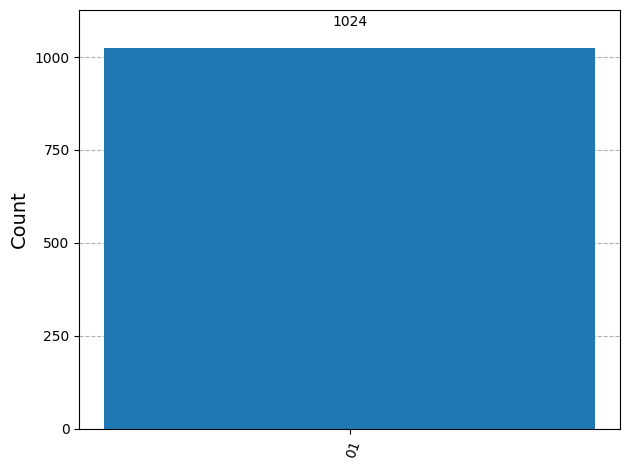

In [3]:
execute_and_plot(circuit=circuit, shots=1024)